In [191]:
import pickle as pkl
import numpy as np
import pandas as pd
import os, sys
import matplotlib.pyplot as plt
import statistics
cmd_folder = os.getenv("SESNPATH") + "/utils"
if cmd_folder not in sys.path:
    sys.path.insert(0, cmd_folder)

from templutils import *
from itertools import combinations


# Setting up

In [192]:
# Reading in the list of bands
su = setupvars()
bands = su.bands

In [193]:
# Use band+p for bands ugri
bands_w_p = [(b + 'p' if b in ['u', 'r', 'i'] else b) for b in bands]

# List of subtypes
types = ['IIb', 'Ib', 'Ibn', 'Ic', 'Ic-bl', 'Ib-c']

In [194]:
allsne_list = pd.read_csv(os.getenv("SESNPATH") +
                                      "utils/allstrippedOpenSNe_z.csv", encoding="ISO-8859-1")

In [195]:
allsne_list['z'][allsne_list.Name == 'sn2010al'].values[0]

'0.017155'

In [196]:
def cal_slope(x, y):
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    return(((y[-1]-y[0])/(x[-1]-x[0])))

In [197]:
# Every combination of 2 bands from the list of all bands
bands_combo = list(combinations(bands_w_p, 2))

## Reading in the file with all data + GP fits

In [198]:
# Read in the file containing all data + GP fits

output_directory = os.getenv("SESNPATH") + "maketemplates/data/"
all_sne = pkl.load(open(output_directory + "all_data.pkl", "rb"))

### Looking at an example SN light curve and its GP fit

In [199]:
# Save the list of SNe names
all_sne_names = list(all_sne.keys()) 
print('Found %i SNe'%len(all_sne_names))

Found 165 SNe


In [200]:
# Let's look at an SN example
name = 'sn2010al'
band = 'up'

sn2010al up 3.3953598484848486
rise rate 0.053849571333625605
decline rate -0.12320555443126911


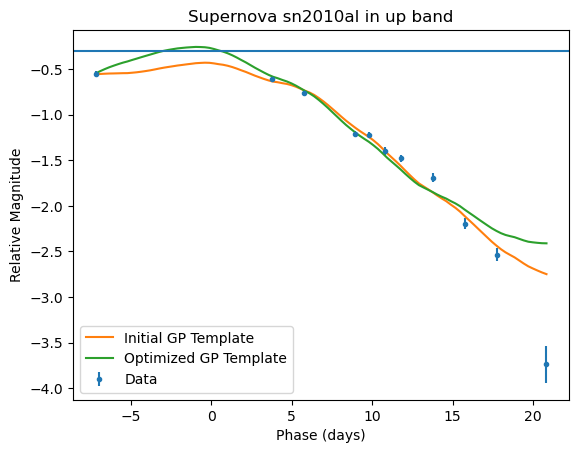

In [203]:
# Plotting data for a SN along with its initial GP fit and its optimized GP fit

plt.errorbar(all_sne[name][band]['x'],
             all_sne[name][band]['y'],
             yerr = all_sne[name][band]['yerr'],
            fmt = '.',
            label = 'Data')
plt.plot(all_sne[name][band]['t'],
         all_sne[name][band]['mu_init']+
         all_sne[name][band]['tmpl_t'],
         '-',
        label = 'Initial GP Template')
plt.plot(all_sne[name][band]['t'],
         all_sne[name][band]['mu_opt']+
         all_sne[name][band]['tmpl_t'],
         '-',
        label = 'Optimized GP Template')
plt.title('Supernova %s in %s band'%(name, band))
plt.xlabel('Phase (days)')
plt.ylabel('Relative Magnitude')
plt.legend()

del_m = 0.05
ind = ((all_sne[name][band]['mu_opt']+
        all_sne[name][band]['tmpl_t'])>np.nanmax(all_sne[name][band]['mu_opt']+
                                        all_sne[name][band]['tmpl_t']-del_m))

pre_ind = (all_sne[name][band]['t']<-2) & (all_sne[name][band]['t']>-10)
post_ind = (all_sne[name][band]['t']>4) & (all_sne[name][band]['t']<10)

phs_peak = all_sne[name][band]['t'][ind]
med_peak = (all_sne[name][band]['mu_opt']+
            all_sne[name][band]['tmpl_t'])[ind]

print(name, band, max(phs_peak)-min(phs_peak))
print('rise rate', cal_slope(all_sne[name][band]['t'][pre_ind],
                     (all_sne[name][band]['mu_opt']+
                    all_sne[name][band]['tmpl_t'])[pre_ind]))
print('decline rate', cal_slope(all_sne[name][band]['t'][post_ind],
                     (all_sne[name][band]['mu_opt']+
                    all_sne[name][band]['tmpl_t'])[post_ind]))


plt.axhline(np.nanmax(all_sne[name][band]['mu_opt']+
                      all_sne[name][band]['tmpl_t'])-del_m)

In [138]:
all_sne[name][band]['mu_opt']+\
        all_sne[name][band]['tmpl_t']

array([-0.54694128, -0.5224515 , -0.50010047, -0.47964919, -0.46167775,
       -0.44478085, -0.42909129, -0.41575569, -0.39991152, -0.38501435,
       -0.36966259, -0.35476899, -0.34037393, -0.3254094 , -0.31106368,
       -0.2988932 , -0.28907524, -0.28059833, -0.27268328, -0.26752632,
       -0.26272772, -0.25941052, -0.25643783, -0.25760076, -0.26005688,
       -0.26691999, -0.27922132, -0.29418653, -0.30790987, -0.32600542,
       -0.34783119, -0.37285656, -0.40020748, -0.42646425, -0.4556839 ,
       -0.48483094, -0.51176331, -0.53843961, -0.56338323, -0.58465245,
       -0.60005926, -0.61850037, -0.63521768, -0.6562525 , -0.68139265,
       -0.71026677, -0.73998632, -0.76616347, -0.79868564, -0.83775547,
       -0.87994456, -0.92495292, -0.9723344 , -1.01967705, -1.06735849,
       -1.11280504, -1.15398   , -1.19388857, -1.23100363, -1.26476329,
       -1.29727125, -1.33486751, -1.37591683, -1.42274718, -1.47159269,
       -1.51489726, -1.55764511, -1.60189895, -1.64857516, -1.69

In [ ]:
reds

In [190]:
bb = 'up'
for key in all_sne.keys():
    
    if bb in all_sne[key].keys():
        
        if all_sne[key]['type']=='Ibn':
            # print(key)
            z = float(allsne_list['z'][allsne_list.Name == key].values[0])
            dist = (z*299792)/70
            app_mag = np.min(all_sne[key]['M_%s_gp'%(bb)])
            abs_mag = app_mag-5*np.log10(dist*10e6)+5
            print(key, 'Ibn', bb[0], 'max_peak=', abs_mag)
            

sn2010al Ibn u max_peak= -23.501104845234686


g 2.3333333333333335 0.8498365855987975
rp 3.1666666666666665 1.0274023338281628
ip 3.0 0.816496580927726


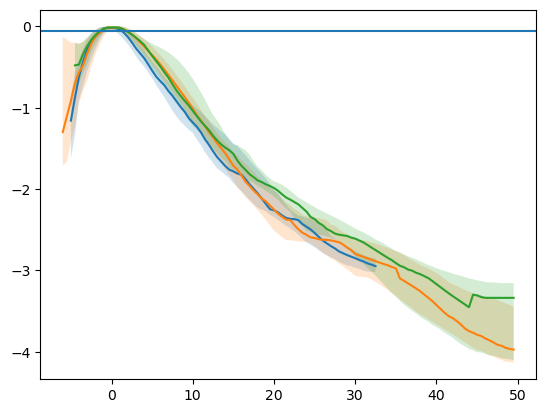

In [129]:
bands2 = ['g', 'rp', 'ip']
for SNTYPE in ['Ibn']:
    tmpl = {}
    for bb in bands2:

        tmpl[bb] = {}

        path = os.getenv("SESNPATH") + "maketemplates/outputs/GP_template_files/GPalltemplfit_%s_%s_V0.pkl"%(SNTYPE,bb)
        tmpl_ = pkl.load(open(path, "rb"))


        if np.nansum(tmpl_['rollingMedian']) == 0:
         # print(bb, SNTYPE)
         continue
        tmpl[bb] = tmpl_
        
        plt.plot(tmpl[bb]['t'], tmpl[bb]['rollingMedian'])
        plt.fill_between(tmpl[bb]['t'], 
                         tmpl[bb]['rollingPc25'],
                         tmpl[bb]['rollingPc75'],
                        alpha=0.2)
        
        del_m = 0.05
        ind = (tmpl[bb]['rollingMedian']>np.nanmax(tmpl[bb]['rollingMedian'])-del_m)
        phs_peak = tmpl[bb]['t'][ind]
        med_peak = tmpl[bb]['rollingMedian'][ind]
        
        ind_up = (tmpl[bb]['rollingPc75']>np.nanmax(tmpl[bb]['rollingPc75'])-del_m)
        phs_peak_up = tmpl[bb]['t'][ind_up]
        med_peak_up = tmpl[bb]['rollingPc75'][ind_up]
        
        ind_down = (tmpl[bb]['rollingPc25']>np.nanmax(tmpl[bb]['rollingPc25'])-del_m)
        phs_peak_down = tmpl[bb]['t'][ind_down]
        med_peak_down = tmpl[bb]['rollingPc25'][ind_down]
        
        print(bb,
              np.mean([max(phs_peak_down)-min(phs_peak_down),
              max(phs_peak)-min(phs_peak),
              max(phs_peak_up)-min(phs_peak_up)]),
              np.std([max(phs_peak_down)-min(phs_peak_down),
              max(phs_peak)-min(phs_peak),
              max(phs_peak_up)-min(phs_peak_up)]))
plt.axhline(np.nanmax(tmpl[bb]['rollingMedian'])-del_m)

In [111]:
# Following the example above, we now save peak magnitude and error for all SNe in all bands

for s, sn in enumerate(all_sne_names):
    for b in bands_w_p:

        if not b in all_sne[sn].keys():
            continue
        if (not 'mu_opt' in all_sne[sn][b].keys()):
            # print('%s in %s/%s bands: No successful GP fits.'%(sn, b_c[0], b_c[1]))
            continue
        t_max_based_on_GP_opt = (all_sne[sn][b]['t'][np.argmax(all_sne[sn][b]['mu_opt']+
                                                             all_sne[sn][b]['tmpl_t'])])
        rel_mag_max_based_on_GP_opt = (all_sne[sn][b]['mu_opt'][np.argmax(all_sne[sn][b]['mu_opt']+
                                                        all_sne[sn][b]['tmpl_t'])]+
                          all_sne[sn][b]['tmpl_t'][np.argmax(all_sne[sn][b]['mu_opt']+
                                                        all_sne[sn][b]['tmpl_t'])])
        error_max_based_on_GP_opt = (all_sne[sn][b]['mu_std_opt'][np.argmax(all_sne[sn][b]['mu_opt']+
                                                            all_sne[sn][b]['tmpl_t'])])

        #check if t_max_based_on_GP_opt is not more than 5 days from the original JDVmax:
        if (np.abs(t_max_based_on_GP_opt)>5):
            # print('%s in %s/%s bands: No data closer than 5 days to the peak'%(sn, b_c[0], b_c[1]))
            continue

        # Find the magnitude of the closest data point to the maximum of the GP fit
        y_mag_closest = all_sne[sn][b]['y_mag'][np.argmin(np.abs(all_sne[sn][b]['x']-t_max_based_on_GP_opt))]

        # Find the relative magnitude of the closest data point to the maximum of the GP fit
        rel_mag_closest = all_sne[sn][b]['y'][np.argmin(np.abs(all_sne[sn][b]['x']-t_max_based_on_GP_opt))]

        # Find how much the relative magnitude is off from the apparent magnitude
        mag_offset = y_mag_closest + rel_mag_closest

        # Find the apparent magnitude of the GP fit peaks using the offset
        mag_max_based_on_GP_opt = mag_offset - rel_mag_max_based_on_GP_opt


        all_sne[sn]['M_%s_gp'%(b)] = mag_max_based_on_GP_opt 
        all_sne[sn]['M_%s_gp_err'%(b)] = rel_mag_max_based_on_GP_opt 

In [94]:
pre_ind = (tmpl[bb]['t']<-2) & (tmpl[bb]['t']>-10)
post_ind = (tmpl[bb]['t']>4) & (tmpl[bb]['t']<10)



0.06691518222620536 0.04475307061542829 0.015471937287085097
0.042380063376239584 0.02106854266411597
-0.142847501922369 -0.1357778684897215 -0.0774885294970494
-0.11870463330304663 0.029286747161222447


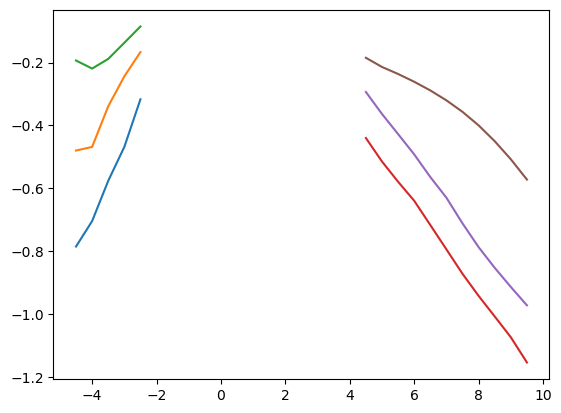

In [146]:
bb ='ip'
plt.plot(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc25'][pre_ind])

plt.plot(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingMedian'][pre_ind])

plt.plot(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc75'][pre_ind])
print(cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc25'][pre_ind]),
               cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingMedian'][pre_ind]),
               cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc75'][pre_ind]))
print(np.mean([cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc25'][pre_ind]),
               cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingMedian'][pre_ind]),
               cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc75'][pre_ind])]),
     np.std([cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc25'][pre_ind]),
               cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingMedian'][pre_ind]),
               cal_slope(tmpl[bb]['t'][pre_ind],
         tmpl[bb]['rollingPc75'][pre_ind])]))

plt.plot(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc25'][post_ind])
print(cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc25'][post_ind]),
      cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingMedian'][post_ind]),
      cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc75'][post_ind]))
print(np.mean([cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc25'][post_ind]),
      cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingMedian'][post_ind]),
      cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc75'][post_ind])]),
     np.std([cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc25'][post_ind]),
      cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingMedian'][post_ind]),
      cal_slope(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc75'][post_ind])]))

plt.plot(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingMedian'][post_ind])


plt.plot(tmpl[bb]['t'][post_ind],
         tmpl[bb]['rollingPc75'][post_ind])
